# e02 - Model Development With and Without Spark MLlib: Evaluation

**Purpose.** Evaluate notebook m16, where the same three model families were trained with scikit-learn (single machine)
and with Spark MLlib pipelines (`VectorAssembler -> Imputer -> StandardScaler -> estimator`, Spark local mode, 6 cores)
on the *same* pixel-grouped folds. Questions:

1. Is the accuracy the same (per crop, tested pair-wise)?
2. What does the framework cost in training time, and how does the gap change with data size?

Reads `results/m16_*.csv` only.

*Duplicate copy kept in `evaluations/` so every model notebook can be found in one place. The maintained source is **`scripts/modeling/e02_spark_mllib_evaluation.ipynb`** — edit it there; this copy is regenerated from it, not edited directly.*

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable regardless of where this notebook is opened from (evaluations/, scripts/modeling/, or
# the project root), unlike a plain cwd-relative lookup.
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "environment.yml").exists())
HERE = PROJECT_ROOT / "scripts" / "modeling"
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import exp_lib as E

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
R = lambda name: pd.read_csv(E.RESULTS_DIR / f"{name}.csv")   # result tables written by the experiment notebooks
CROP_NAMES = {"rice": "Rice", "maize": "Maize", "cassava": "Cassava", "soybean": "Soybean", "oilpalm": "Oil palm",
              "rubber": "Rubber", "sugarcane": "Sugarcane", "coffee": "Coffee", "cacao": "Cacao", "coconut": "Coconut"}
MODEL_NAMES = {"et": "ExtraTrees", "xgb": "XGBoost", "hgb": "HistGB", "knn": "kNN", "ridge": "Ridge",
               "dummy": "Mean baseline", "logreg": "Logistic reg."}

## 1. Accuracy and time side by side

In [2]:
s = R("m16_summary").rename(columns={"wall seconds (10 crops x 5 folds)": "seconds (50 fits)"})
s

,framework,model,r2,rmse,spearman,seconds (50 fits)
0,scikit-learn,Linear (ridge),0.6038,1313.00,0.7746,1.2229
1,scikit-learn,Random forest,0.8077,902.60,0.8943,11.2070
2,scikit-learn,Gradient boosting,0.7971,929.21,0.8909,2.8922
3,scikit-learn,ExtraTrees (reference),0.8191,876.43,0.9006,11.9190
4,Spark MLlib,Linear (ridge),0.6038,1312.90,0.7746,28.2740
5,Spark MLlib,Random forest,0.8062,907.12,0.8942,240.5700
6,Spark MLlib,Gradient boosting,0.7604,1010.90,0.8730,155.4600


In [3]:
cv = R("m16_cv_raw")
cv["crop"] = cv["crop"].map(CROP_NAMES)
fam = {"Linear (ridge)": "Linear", "Random forest": "Random forest", "Gradient boosting": "Gradient boosting"}
paired = (cv[cv["model"].isin(fam)].pivot_table(index=["model", "crop"], columns="framework", values=["r2", "rmse", "spearman"]))
paired.columns = [f"{m} {f}" for m, f in paired.columns]
paired["ΔR² (Spark - sklearn)"] = paired["r2 Spark MLlib"] - paired["r2 scikit-learn"]
E.save_table(paired.reset_index(), "e02_paired_per_crop")
paired.round(3)

r2 Spark MLlib  r2 scikit-learn  rmse Spark MLlib  rmse scikit-learn  spearman Spark MLlib  spearman scikit-learn  \
model             crop                                                                                                                           
Gradient boosting Cacao               0.769            0.796           1010.40             949.20                 0.876                  0.889   
                  Cassava             0.770            0.819           1314.40            1166.80                 0.875                  0.902   
                  Coconut             0.788            0.825           1499.00            1363.40                 0.888                  0.906   
                  Coffee              0.792            0.812           1273.40            1210.00                 0.889                  0.899   
                  Maize               0.745            0.782            509.05             470.77                 0.870                  0.890   
                  Oil palm            0.781            0.812           1297.00            1204.00                 0.880                  0.898   
                  Rice                0.792            0.829           1122.40            1018.10                 0.878                  0.904   
                  Rubber              0.686            0.732            511.50             472.82                 0.826                  0.835   
                  Soybean             0.692            0.740            762.25             701.13                 0.865                  0.883   
                  Sugarcane           0.789            0.826            809.84             735.79                 0.883                  0.903   
Linear (ridge)    Cacao               0.616            0.616           1303.90            1304.00                 0.785                  0.785   
                  Cassava             0.614            0.614           1704.40            1704.70                 0.778                  0.778   
                  Coconut             0.644            0.644           1943.40            1943.50                 0.792                  0.792   
                  Coffee              0.607            0.607           1747.80            1748.00                 0.774                  0.774   
                  Maize               0.616            0.616            623.97             624.05                 0.782                  0.782   
                  Oil palm            0.609            0.609           1734.20            1734.60                 0.776                  0.776   
                  Rice                0.645            0.645           1466.50            1466.70                 0.786                  0.786   
                  Rubber              0.467            0.466            667.00             667.06                 0.695                  0.695   
                  Soybean             0.561            0.561            909.70             909.69                 0.781                  0.781   
                  Sugarcane           0.660            0.660           1027.60            1027.70                 0.798                  0.798   
Random forest     Cacao               0.797            0.800            947.01             940.53                 0.890                  0.892   
                  Cassava             0.825            0.826           1148.30            1143.10                 0.903                  0.903   
                  Coconut             0.839            0.842           1305.40            1293.10                 0.912                  0.911   
                  Coffee              0.824            0.824           1170.60            1170.40                 0.903                  0.903   
                  Maize               0.794            0.794            456.60             456.62                 0.893                  0.893   
                  Oil palm            0.819            0.817           1179.60         

In [4]:
rows = []
for m in fam:
    g = paired.loc[m]
    w = stats.wilcoxon(g["r2 scikit-learn"], g["r2 Spark MLlib"]) if (g["ΔR² (Spark - sklearn)"].abs() > 1e-4).any() else None
    sec = s.set_index(["framework", "model"])["seconds (50 fits)"]
    rows.append({"model": m, "mean ΔR²": g["ΔR² (Spark - sklearn)"].mean(), "max |ΔR²|": g["ΔR² (Spark - sklearn)"].abs().max(),
                 "Wilcoxon p (10 crops)": w.pvalue if w else np.nan,
                 "time ratio Spark / sklearn": sec[("Spark MLlib", m)] / sec[("scikit-learn", m)]})
verdict = pd.DataFrame(rows)
E.save_table(verdict, "e02_verdict")
verdict.round(4)

,model,mean ΔR²,max |ΔR²|,Wilcoxon p (10 crops),time ratio Spark / sklearn
0,Linear (ridge),0.0001,0.0001,NaN,23.1205
1,Random forest,-0.0014,0.0075,0.250,21.4660
2,Gradient boosting,-0.0367,0.0487,0.002,53.7515


**Reading.** Linear regression is identical in both frameworks (same closed-form problem). Random forest differs by
0.001 R² on average (at most 0.008 for one crop; Wilcoxon p = 0.25 over 10 crops), within the noise of the random
trees. Gradient boosting is clearly weaker in MLlib (-0.037 R², lower on all 10 crops, p = 0.002) (GBTRegressor fits
depth-limited trees sequentially without the histogram tricks and early stopping of HistGradientBoosting), so the gap is
an algorithm-implementation difference, not a data-volume effect.

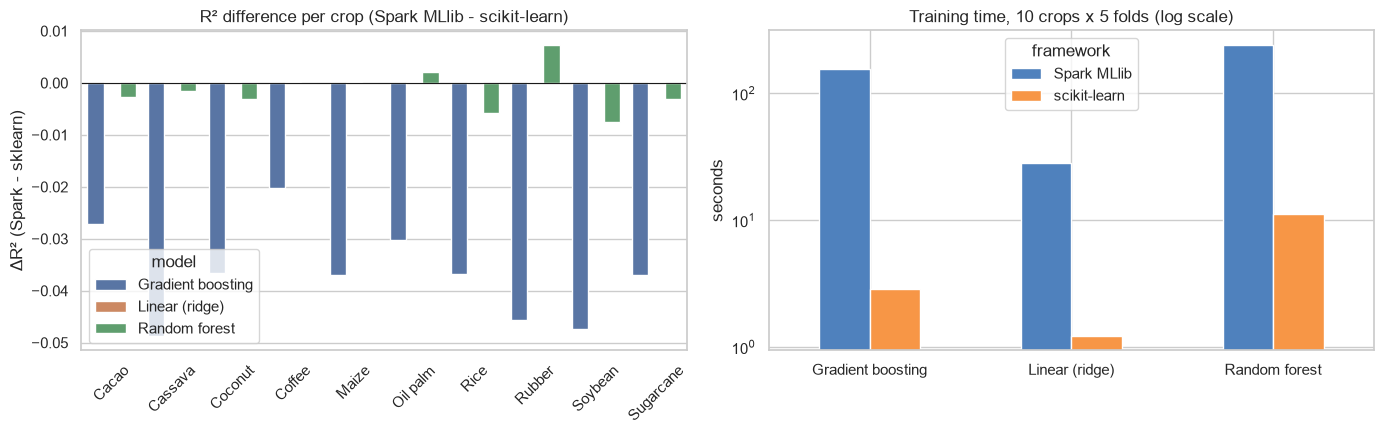

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
d = paired.reset_index()
sns.barplot(data=d, x="crop", y="ΔR² (Spark - sklearn)", hue="model", ax=ax[0])
ax[0].axhline(0, color="k", lw=0.8); ax[0].tick_params(axis="x", rotation=45)
ax[0].set(title="R² difference per crop (Spark MLlib - scikit-learn)", xlabel="")
t = s.pivot(index="model", columns="framework", values="seconds (50 fits)").drop(index="ExtraTrees (reference)")
t.plot.bar(ax=ax[1], logy=True, rot=0, color=["#4f81bd", "#f79646"])
ax[1].set(title="Training time, 10 crops x 5 folds (log scale)", ylabel="seconds", xlabel="")
fig.tight_layout()
E.save_fig(fig, "e02_accuracy_time");

## 2. Scalability: training time against the number of rows

m16 replicated the training table 1x, 4x and 16x and timed one random forest (rice, 30 trees). A power law
`time = a * rows^b` fitted on the three points gives the growth exponent b of each framework; where the two curves meet is
a rough estimate of the data size at which Spark's fixed overhead stops dominating on this machine.

In [6]:
sc = R("m16_scaling")
x = sc["training rows"].to_numpy(float)
fit = {}
for col in ["scikit-learn (s)", "Spark MLlib (s)"]:
    b, log_a = np.polyfit(np.log(x), np.log(sc[col]), 1)
    fit[col] = (np.exp(log_a), b)
(a1, b1), (a2, b2) = fit.values()
cross = (a2 / a1) ** (1 / (b1 - b2)) if b1 > b2 else np.inf
sc["ratio Spark / sklearn"] = sc["Spark MLlib (s)"] / sc["scikit-learn (s)"]
print({k: f"time = {a:.2e} * rows^{b:.2f}" for k, (a, b) in fit.items()})
print(f"curves meet at roughly {cross:,.0f} rows (extrapolated far beyond the measured range; order of magnitude only)")
E.save_table(sc, "e02_scaling")
sc.round(3)

{'scikit-learn (s)': 'time = 2.35e-05 * rows^0.95', 'Spark MLlib (s)': 'time = 3.33e-01 * rows^0.30'}
curves meet at roughly 2,485,828 rows (extrapolated far beyond the measured range; order of magnitude only)


,training rows,scikit-learn (s),Spark MLlib (s),ratio Spark / sklearn
0,7162,0.108,4.804,44.481
1,28648,0.373,6.778,18.172
2,114592,1.493,10.983,7.356


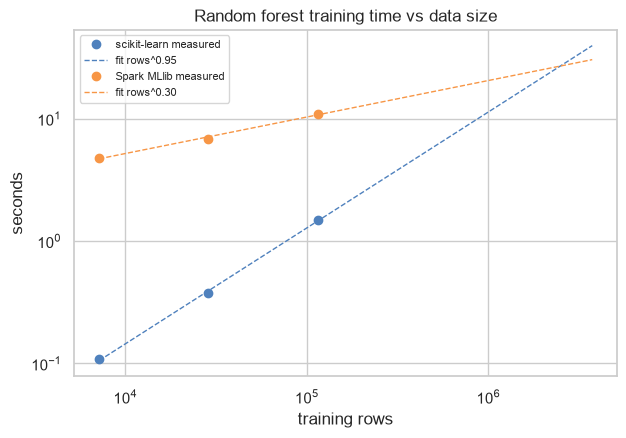

In [7]:
xs = np.logspace(np.log10(x.min()), np.log10(max(x.max() * 10, min(cross, 1e9) * 1.5)), 100)
fig, ax = plt.subplots(figsize=(7, 4.5))
for (col, (a, b)), colr in zip(fit.items(), ["#4f81bd", "#f79646"]):
    ax.loglog(x, sc[col], "o", color=colr, label=f"{col[:-4]} measured")
    ax.loglog(xs, a * xs ** b, "--", color=colr, lw=1, label=f"fit rows^{b:.2f}")
ax.set(xlabel="training rows", ylabel="seconds", title="Random forest training time vs data size")
ax.legend(fontsize=8)
E.save_fig(fig, "e02_scaling");

**Conclusion.** At the province scale (9,129 cells) scikit-learn is as accurate and 21-54x faster over the full
cross-validation (7-45x in the scaling test). Spark's cost is mostly a fixed JVM/scheduling overhead: its time grows
with rows^0.30 against rows^0.95 for scikit-learn, so the ratio falls from 44x to 7x over a 16-fold increase in data,
and the fitted curves meet at the order of a few million rows (an extrapolation, not a measurement). The pipeline is therefore written so that the identical MLlib version can take over when the grid grows
to national or multi-temporal scale (millions of cells), which a single machine's memory would not hold.